In [1]:
from mplsoccer import VerticalPitch
import matplotlib.pyplot as plt
import os
import pandas as pd
import pickle

In [2]:
seed = 123

In [ ]:
events_df = pd.concat(
    [pd.read_parquet(f"../data/events/{df}") for df in os.listdir("../data/events") if df.endswith(".parquet")]
)

In [3]:
events_df["start_x"] = events_df["location"].apply(
    lambda loc: loc[0] if isinstance(loc, (list, tuple)) and len(loc) > 0 else None
)

events_df["start_y"] = events_df["location"].apply(
    lambda loc: loc[1] if isinstance(loc, (list, tuple)) and len(loc) > 1 else None
)

<positron-console-cell-3>:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-3>:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


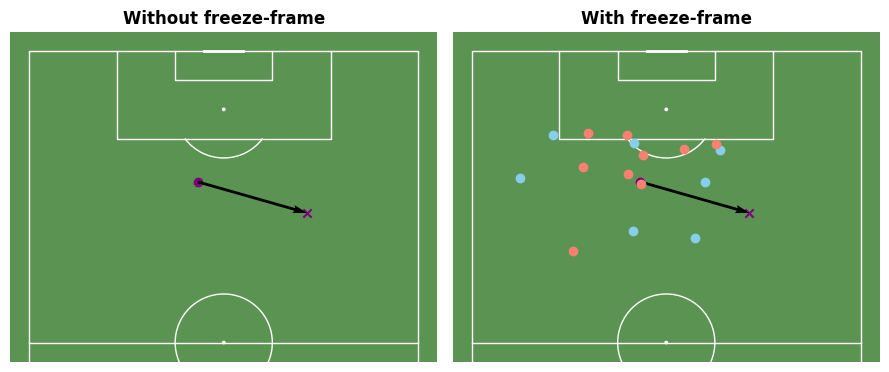

In [13]:
pitch = VerticalPitch(
    half=True,
    line_color="white",
    linewidth=1,
    pitch_color="#5B9452"
)

fig, axs = plt.subplots(1, 2, figsize=(9, 4))

pitch_data = events_df[
    events_df["id"] == "23b6b26a-293c-4d5e-9889-5a5ce0b7ad8c"
]

event_type = pitch_data["type"].item().lower()

x_start = pitch_data["location"].item()[0]
y_start = pitch_data["location"].item()[1]

x_end = pitch_data[f"{event_type}_end_location"].item()[0]
y_end = pitch_data[f"{event_type}_end_location"].item()[1]

freeze_frame = pitch_data["freeze_frame"].item()

pitch.draw(ax=axs[0])

pitch.scatter(x_start, y_start, color="purple", ax=axs[0])
pitch.scatter(x_end, y_end, color="purple", marker="x", ax=axs[0])

pitch.arrows(
    xstart=x_start,
    ystart=y_start,
    xend=x_end,
    yend=y_end,
    ax=axs[0],
    width=2
)

axs[0].set_title("Without freeze-frame", fontweight="bold")

pitch.draw(ax=axs[1])

pitch.scatter(x_start, y_start, color="purple", ax=axs[1])
pitch.scatter(x_end, y_end, color="purple", marker="x", ax=axs[1])

pitch.arrows(
    xstart=x_start,
    ystart=y_start,
    xend=x_end,
    yend=y_end,
    ax=axs[1],
    width=2
)

for x in freeze_frame:
    if not x["actor"]:
        colour = "skyblue" if x["teammate"] else "salmon"
        pitch.scatter(
            x["location"][0],
            x["location"][1],
            color=colour,
            ax=axs[1]
        )

axs[1].set_title("With freeze-frame", fontweight="bold")

plt.tight_layout()
plt.savefig("../reports/research-proposal/figures/intro_event_example.png", dpi=600)
plt.show()

with open("../data/metadata/intro_event_example_id.pkl", "wb") as f:
    intro_event_example_id = pitch_data["id"].item()
    pickle.dump(intro_event_example_id, f)

with open("../data/metadata/intro_event_example_shot_id.pkl", "wb") as f:
    intro_event_example_shot_id = pitch_data["pass_assisted_shot_id"].item()
    pickle.dump(intro_event_example_shot_id, f)

In [14]:
pd.DataFrame({
    "Item": [
        "OS", 
        "CPU", 
        "RAM", 
        "GPU",
        "Programming Language",
        "Libraries",
        "Technical Publishing System",
        "IDE"
    ],
    "Value": [
        "Windows 11", 
        "AMD Ryzen 5 3600 6-Core Processor (3.6 GHz)", 
        "16GB", 
        "Nvidia GeForce RTX 3070 8GB VRAM",
        "Python 3.12.10",
        "pandas, numpy, scipy, matplotlib, seaborn, scikit-learn, pytorch, statsmodels, statsbombpy, socceraction, mplsoccer",
        "Quarto 1.6.42",
        "Positron 2026.04.1"
    ]
}).to_csv("../data/metadata/project_resources.csv", index=False)
